# Problem 2: MNIST class and testing with my own digits
Forward propagation of a 3-layer network (784-50-100-10, sigmoid, sigmoid, softmax) using the
pre-trained weights in `mnist/sample_weight.pkl`.
Test images live in `images/` and are named `n_m.png` (digit `n`, version `m`), 28x28 grayscale,
white digit on black background (MNIST convention).

In [1]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
class Mnist:
    """Forward propagation (inference) for the pre-trained MNIST network."""

    def __init__(self, model_file="mnist/sample_weight.pkl"):
        with open(model_file, "rb") as f:
            self.network = pickle.load(f)

    # --- activation functions
    @staticmethod
    def sigmoid(a):
        return 1 / (1 + np.exp(-a))

    @staticmethod
    def softmax(a):
        c = np.max(a)                 # subtract max for numerical stability
        e = np.exp(a - c)
        return e / np.sum(e)

    # --- forward propagation
    def predict(self, x):
        w1, w2, w3 = self.network["W1"], self.network["W2"], self.network["W3"]
        b1, b2, b3 = self.network["b1"], self.network["b2"], self.network["b3"]
        z1 = self.sigmoid(np.dot(x, w1) + b1)
        z2 = self.sigmoid(np.dot(z1, w2) + b2)
        return self.softmax(np.dot(z2, w3) + b3)

    # --- image handling
    @staticmethod
    def load_image(path):
        """Open as 28x28 grayscale; return (2-D uint8 array for display, flat float vector in [0,1])."""
        img = Image.open(path).convert("L")
        if img.size != (28, 28):
            img = img.resize((28, 28))
        arr = np.array(img)
        return arr, arr.reshape(-1) / 255.0

    def classify(self, path, show=True):
        """Classify `path` (named n_m.png); show the input with imshow; print Success/Fail."""
        name = os.path.basename(path)
        expected = int(name.split("_")[0])
        arr, x = self.load_image(path)
        result = int(np.argmax(self.predict(x)))

        if show:
            plt.figure(figsize=(1.6, 1.6))
            plt.imshow(arr, cmap="gray")
            plt.title(name, fontsize=9)
            plt.axis("off")
            plt.show()

        if result == expected:
            print(f"Success: Image {name} is for digit {expected} is recognized as {result}.")
        else:
            print(f"Fail: Image {name} is for digit {expected} but the inference result is {result}.")
        return result == expected

## Sanity check on an MNIST test image

In [3]:
import gzip
with gzip.open("mnist/t10k-images-idx3-ubyte.gz", "rb") as f:
    X_test = np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, 784)
with gzip.open("mnist/t10k-labels-idx1-ubyte.gz", "rb") as f:
    y_test = np.frombuffer(f.read(), np.uint8, offset=8)

mnist = Mnist()
n = 100
y = mnist.predict(X_test[n] / 255.0)
print("label:", y_test[n], "prediction:", np.argmax(y), "certainty: %.3f" % np.max(y))

label: 6 prediction: 6 certainty: 0.952


C:\Users\Sathwik\AppData\Local\Temp\ipykernel_35580\1149539317.py:6: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  self.network = pickle.load(f)


## My digit images (5 per digit)

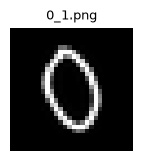

Success: Image 0_1.png is for digit 0 is recognized as 0.


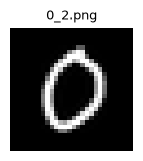

Success: Image 0_2.png is for digit 0 is recognized as 0.


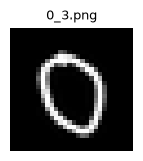

Success: Image 0_3.png is for digit 0 is recognized as 0.


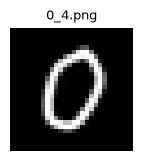

Success: Image 0_4.png is for digit 0 is recognized as 0.


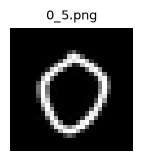

Success: Image 0_5.png is for digit 0 is recognized as 0.


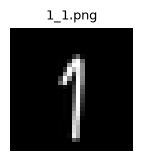

Fail: Image 1_1.png is for digit 1 but the inference result is 7.


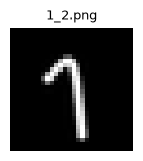

Fail: Image 1_2.png is for digit 1 but the inference result is 7.


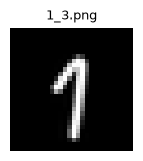

Fail: Image 1_3.png is for digit 1 but the inference result is 9.


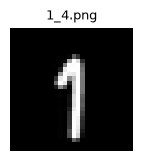

Success: Image 1_4.png is for digit 1 is recognized as 1.


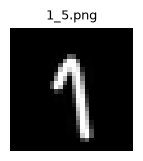

Fail: Image 1_5.png is for digit 1 but the inference result is 9.


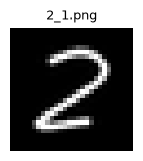

Success: Image 2_1.png is for digit 2 is recognized as 2.


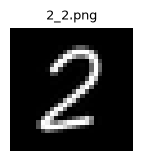

Success: Image 2_2.png is for digit 2 is recognized as 2.


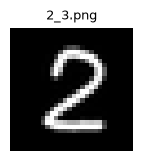

Success: Image 2_3.png is for digit 2 is recognized as 2.


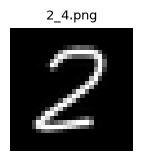

Success: Image 2_4.png is for digit 2 is recognized as 2.


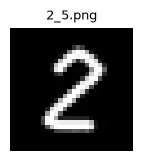

Success: Image 2_5.png is for digit 2 is recognized as 2.


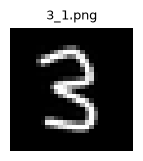

Success: Image 3_1.png is for digit 3 is recognized as 3.


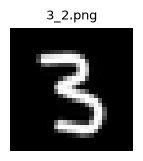

Success: Image 3_2.png is for digit 3 is recognized as 3.


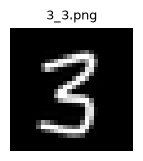

Success: Image 3_3.png is for digit 3 is recognized as 3.


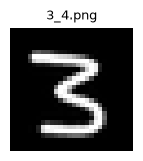

Success: Image 3_4.png is for digit 3 is recognized as 3.


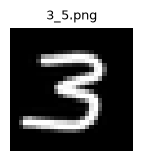

Success: Image 3_5.png is for digit 3 is recognized as 3.


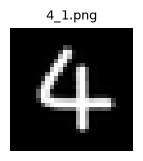

Success: Image 4_1.png is for digit 4 is recognized as 4.


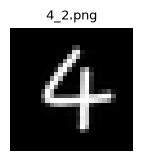

Success: Image 4_2.png is for digit 4 is recognized as 4.


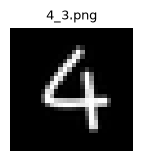

Success: Image 4_3.png is for digit 4 is recognized as 4.


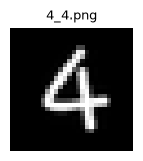

Success: Image 4_4.png is for digit 4 is recognized as 4.


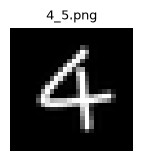

Success: Image 4_5.png is for digit 4 is recognized as 4.


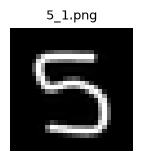

Success: Image 5_1.png is for digit 5 is recognized as 5.


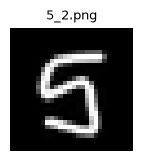

Success: Image 5_2.png is for digit 5 is recognized as 5.


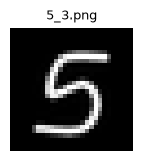

Success: Image 5_3.png is for digit 5 is recognized as 5.


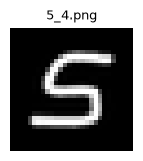

Success: Image 5_4.png is for digit 5 is recognized as 5.


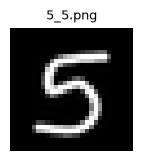

Success: Image 5_5.png is for digit 5 is recognized as 5.


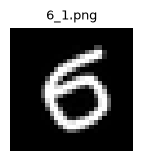

Success: Image 6_1.png is for digit 6 is recognized as 6.


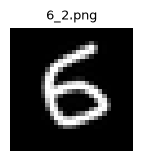

Success: Image 6_2.png is for digit 6 is recognized as 6.


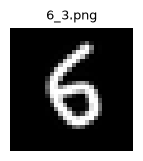

Success: Image 6_3.png is for digit 6 is recognized as 6.


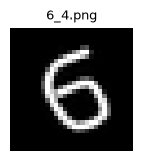

Success: Image 6_4.png is for digit 6 is recognized as 6.


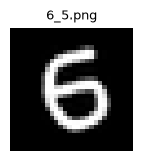

Success: Image 6_5.png is for digit 6 is recognized as 6.


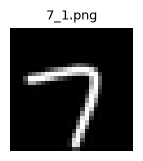

Success: Image 7_1.png is for digit 7 is recognized as 7.


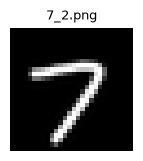

Success: Image 7_2.png is for digit 7 is recognized as 7.


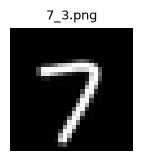

Success: Image 7_3.png is for digit 7 is recognized as 7.


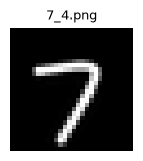

Success: Image 7_4.png is for digit 7 is recognized as 7.


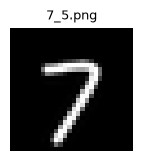

Success: Image 7_5.png is for digit 7 is recognized as 7.


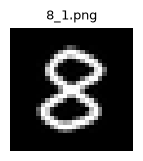

Success: Image 8_1.png is for digit 8 is recognized as 8.


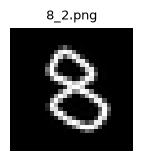

Success: Image 8_2.png is for digit 8 is recognized as 8.


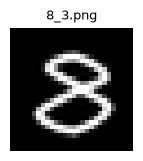

Success: Image 8_3.png is for digit 8 is recognized as 8.


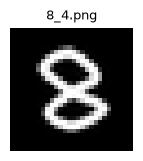

Success: Image 8_4.png is for digit 8 is recognized as 8.


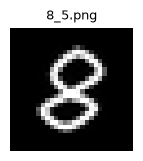

Success: Image 8_5.png is for digit 8 is recognized as 8.


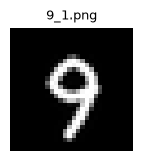

Success: Image 9_1.png is for digit 9 is recognized as 9.


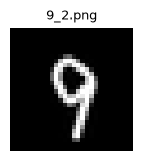

Success: Image 9_2.png is for digit 9 is recognized as 9.


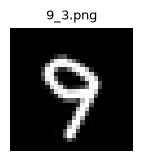

Success: Image 9_3.png is for digit 9 is recognized as 9.


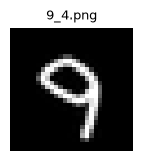

Success: Image 9_4.png is for digit 9 is recognized as 9.


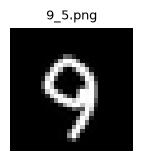

Success: Image 9_5.png is for digit 9 is recognized as 9.

Accuracy on my images: 46/50 = 92%


In [4]:
results = []
for digit in range(10):
    for ver in range(1, 6):
        results.append(mnist.classify(f"images/{digit}_{ver}.png"))
print(f"\nAccuracy on my images: {sum(results)}/{len(results)} = {np.mean(results):.0%}")